# Inverse PINN: Jet-Impingement Heat Transfer

This notebook solves a jet-impingement inverse heat-transfer problem with a 2-D PyTorch PINN.

Methodology:

- 2-D interior collocation sampling with LHS or Sobol options
- separate boundary sampling for bottom, top, left, and right edges
- autograd Hessian for `theta_xx + theta_yy`
- separate loss terms for PDE, Dirichlet, Robin, sensor data, and optional nodal smoothness
- per-loss monitoring during training
- Adam + cosine annealing followed by L-BFGS fine tuning
- FDM benchmark comparison with field/error maps

Inverse target:

`BI_MODEL_CONFIG['type']` selects either `gaussian` or `discrete_nodal` for `Bi_top(x*)`.


In [1]:
from pathlib import Path
import csv
import json
import math
import os
import random
import sys
import time

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
import numpy as np
import sympy
import sympy.printing
import torch
import torch.nn as nn
from torch.optim.lr_scheduler import CosineAnnealingLR
from scipy.interpolate import PchipInterpolator

if not hasattr(sympy, "printing"):
    sympy.printing = sys.modules["sympy.printing"]


torch.set_default_dtype(torch.float64)

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)


device: cuda


## 1. Load FDM Reference Data

The FDM solution supplies the benchmark field and nondimensional constants. Sensor placement is configured in this notebook, then clean sensor values are sampled from the FDM field.

In [2]:
NOTEBOOK_DIR = Path.cwd()
REF_PATH = NOTEBOOK_DIR / "fdm_reference_output" / "fdm_reference_jet_impingement.npz"
if not REF_PATH.exists():
    REF_PATH = Path("/home/jinooson/DL_study/Heat_Transfer_PINN/Final_Project/fdm_reference_output/fdm_reference_jet_impingement.npz")

data = np.load(REF_PATH)

xs = data["xs"]
ys = data["ys"]
theta_ref = data["theta"]

Q_STAR = float(data["Q_STAR"])
BI_SIDE = float(data["BI_SIDE"])
L = float(data["L"])
D_JET = float(data["D_jet"])
K_S = float(data["k_s"])
T_B = float(data["T_b"])
T_INF = float(data["T_inf"])
R_OVER_D_DATA = data["R_over_D_data"]
H_DATA = data["h_data"]
X_JET = 0.5

USE_NOISY_SENSOR = False
NOISE_LEVEL_THETA = 0.02
NOISE_SEED = SEED + 100

def make_sensor_points(sensor_x, sensor_y):
    if isinstance(sensor_x[0], (list, tuple, np.ndarray)):
        if len(sensor_x) != len(sensor_y):
            raise ValueError("row-wise sensor_x must have the same length as sensor_y.")
        return np.array([[x, y] for y, xs_row in zip(sensor_y, sensor_x) for x in xs_row], dtype=float)
    return np.array([[x, y] for y in sensor_y for x in sensor_x], dtype=float)

def sample_bilinear(xs, ys, field, points):
    values = []
    for x, y in np.asarray(points):
        i = np.clip(np.searchsorted(xs, x) - 1, 0, len(xs) - 2)
        j = np.clip(np.searchsorted(ys, y) - 1, 0, len(ys) - 2)
        tx = (x - xs[i]) / (xs[i + 1] - xs[i])
        ty = (y - ys[j]) / (ys[j + 1] - ys[j])
        values.append(
            (1 - tx) * (1 - ty) * field[j, i]
            + tx * (1 - ty) * field[j, i + 1]
            + (1 - tx) * ty * field[j + 1, i]
            + tx * ty * field[j + 1, i + 1]
        )
    return np.asarray(values).reshape(-1, 1)

def build_sensor_theta_y_fd_data(points, theta_values, x_round_decimals=12):
    """Build theta_y labels only from vertically paired sensor temperatures."""
    points = np.asarray(points, dtype=float)
    theta_values = np.asarray(theta_values, dtype=float).reshape(-1, 1)

    by_x = {}
    for idx, (x, _y) in enumerate(points):
        by_x.setdefault(round(float(x), x_round_decimals), []).append(idx)

    lower_points = []
    upper_points = []
    pair_points = []
    theta_y_values = []

    for indices in by_x.values():
        if len(indices) < 2:
            continue
        ordered = sorted(indices, key=lambda i: points[i, 1])
        for lower_idx, upper_idx in zip(ordered[:-1], ordered[1:]):
            y_lower = float(points[lower_idx, 1])
            y_upper = float(points[upper_idx, 1])
            dy_pair = y_upper - y_lower
            if dy_pair <= 0.0:
                continue
            lower_points.append(points[lower_idx])
            upper_points.append(points[upper_idx])
            pair_points.append([points[lower_idx, 0], 0.5 * (y_lower + y_upper)])
            theta_y_values.append((theta_values[upper_idx, 0] - theta_values[lower_idx, 0]) / dy_pair)

    if not theta_y_values:
        empty_points = np.empty((0, 2), dtype=float)
        empty_values = np.empty((0, 1), dtype=float)
        return empty_points, empty_points.copy(), empty_points.copy(), empty_values

    return (
        np.asarray(lower_points, dtype=float),
        np.asarray(upper_points, dtype=float),
        np.asarray(pair_points, dtype=float),
        np.asarray(theta_y_values, dtype=float).reshape(-1, 1),
    )

# Add noise into clean Sensor Values
def gaussian_sensor_noise(shape, noise_level_theta, seed):
    raw = np.random.default_rng(seed).normal(size=shape)
    raw = raw - raw.mean()
    return noise_level_theta * raw / max(raw.std(), 1e-12)

# Load the Empirical Data of h(x)
bi_interp = PchipInterpolator(R_OVER_D_DATA, H_DATA * L / K_S, extrapolate=True)
def true_bi_numpy(x_star):
    r_over_d = np.abs(np.asarray(x_star) - X_JET) * L / D_JET
    r_over_d = np.clip(r_over_d, R_OVER_D_DATA.min(), R_OVER_D_DATA.max())
    if bi_interp is not None:
        return np.maximum(bi_interp(r_over_d), 1e-12)
    return np.maximum(np.interp(r_over_d, R_OVER_D_DATA, H_DATA * L / K_S), 1e-12)

# dimensionalize theta into Temperature[C]
def to_temperature(theta):
    return T_INF + theta * (T_B - T_INF)

print("reference:", REF_PATH)
print("theta_ref shape:", theta_ref.shape)
print(f"Q*={Q_STAR:.6g}, Bi_side={BI_SIDE:.6g}, Bi_top range=({true_bi_numpy(xs).min():.4g}, {true_bi_numpy(xs).max():.4g})")


reference: /home/jinooson/DL_study/Heat_Transfer_PINN/Final_Project/fdm_reference_output/fdm_reference_jet_impingement.npz
theta_ref shape: (121, 121)
Q*=1.06667, Bi_side=0.01, Bi_top range=(0.268, 0.828)


## 2. 2-D Sampling Method

Interior collocation points are sampled in the rectangular domain with either LHS or Sobol sampling. Boundary points are built edge-by-edge so different boundary conditions can have different point counts and weights.

In [3]:
# lhs sampling function
def sample_interior_lhs(n, seed=0, device=DEVICE, requires_grad=True):
    """Latin Hypercube samples in [0,1] x [0,1]."""
    rng = np.random.default_rng(seed)
    edges = np.linspace(0.0, 1.0, n + 1)
    x = rng.uniform(edges[:-1], edges[1:])
    y = rng.uniform(edges[:-1], edges[1:])
    rng.shuffle(x)
    rng.shuffle(y)
    xy = np.stack([x, y], axis=1)
    out = torch.tensor(xy, dtype=torch.float64, device=device)
    return out.requires_grad_(requires_grad)

# sobol sampling function
def sample_interior_sobol(n, seed=0, device=DEVICE, requires_grad=True):
    """Scrambled Sobol samples in [0,1] x [0,1]."""
    engine = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=seed)
    out = engine.draw(n).to(dtype=torch.float64, device=device)
    return out.requires_grad_(requires_grad)

# boundary sampling
def edge_points(edge, n, mode="uniform", seed=0, device=DEVICE, requires_grad=False):
    """Sample one rectangular edge: bottom, top, left, or right."""
    if mode == "uniform":
        s = torch.linspace(0.0, 1.0, n, dtype=torch.float64, device=device).reshape(-1, 1)
    elif mode == "random":
        gen = torch.Generator(device="cpu")
        gen.manual_seed(seed)
        s = torch.rand(n, 1, generator=gen, dtype=torch.float64).to(device)
    else:
        raise ValueError(f"unknown edge sampling mode: {mode}")

    z = torch.zeros_like(s)
    o = torch.ones_like(s)
    if edge == "bottom":
        xy = torch.cat([s, z], dim=1)
    elif edge == "top":
        xy = torch.cat([s, o], dim=1)
    elif edge == "left":
        xy = torch.cat([z, s], dim=1)
    elif edge == "right":
        xy = torch.cat([o, s], dim=1)
    else:
        raise ValueError(f"unknown edge: {edge}")
    return xy.requires_grad_(requires_grad)

# Create interior and edge points based on configuration parameters
def make_training_points(n_domain, n_boundary, sampling="lhs", boundary_mode="uniform", seed=0):
    """Generate interior collocation points and unified edge boundary points."""
    if sampling == "lhs":
        xy_f = sample_interior_lhs(n_domain, seed=seed, requires_grad=True)
    elif sampling == "sobol":
        xy_f = sample_interior_sobol(n_domain, seed=seed, requires_grad=True)
    else:
        raise ValueError("sampling must be either 'lhs' or 'sobol'.")
    boundary = {
        "bottom": edge_points("bottom", n_boundary, mode=boundary_mode, seed=seed + 1),
        "top": edge_points("top", n_boundary, mode=boundary_mode, seed=seed + 2),
        "left": edge_points("left", n_boundary, mode=boundary_mode, seed=seed + 3),
        "right": edge_points("right", n_boundary, mode=boundary_mode, seed=seed + 4),
    }
    return xy_f, boundary


def mse(x):
    return torch.mean(x ** 2)


## 3. Network and Bi Top Boundary Models

The PINN maps `(x*, y*) -> theta`. The inverse part can use Gaussian, discrete nodal, or auxiliary-NN models for the unknown top-wall Biot profile.


In [4]:
# Define PINN model
class PINN2D(nn.Module):
    def __init__(self):
        super().__init__()
        # 4 hidden layers (2 -> 64 -> 64 -> 64 -> 64 -> 1)
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )
        for m in self.net.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, xy):
        return self.net(xy)

# Optional baseline: Gaussian parameters as the inverse-problem training variables.
class GaussianBiTop(nn.Module):
    """Symmetric double-Gaussian-with-background Bi_top model."""
    def __init__(self, init_bi_max, init_bi_min):
        super().__init__()
        self.softplus = nn.Softplus()

        init_background = max(float(init_bi_min), 1e-4)
        init_primary_amp = max(float(init_bi_max) - init_background, 1e-4)
        init_ring_amp = max(0.35 * init_primary_amp, 1e-4)
        init_delta = 0.20
        init = torch.tensor([ # initial guess of Gaussian Parameters
            self._inv_softplus(init_primary_amp),   #theta1
            self._inv_softplus(0.08),               #theta2
            self._inv_softplus(init_ring_amp),      #theta3
            self._logit(init_delta / 0.5),          #theta4
            self._inv_softplus(0.15),               #theta5
            self._inv_softplus(init_background),    #theta6
        ], dtype=torch.float64)
        self.raw = nn.Parameter(init) # define raw as the training variable with an initial guess

    @staticmethod
    def _inv_softplus(y): # inverse softplus for usage of nn.Softplus
        return math.log(math.exp(float(y)) - 1.0)

    @staticmethod
    def _logit(p): # inverse sigmoid to limit theta_4 from exceeding 0.5 (geometry limit)
        p = min(max(float(p), 1e-6), 1.0 - 1e-6)
        return math.log(p / (1.0 - p))

    def physical_params(self): # convert Raw parameters --(softplus or sigmoid)--> Physical parameters
        theta1 = self.softplus(self.raw[0])              # center peak amplitude
        theta2 = self.softplus(self.raw[1]) + 1e-4       # center peak width
        theta3 = self.softplus(self.raw[2])              # symmetric ring peak amplitude
        theta4 = 0.5 * torch.sigmoid(self.raw[3])        # ring offset from jet center
        theta5 = self.softplus(self.raw[4]) + 1e-4       # ring peak width
        theta6 = self.softplus(self.raw[5]) + 1e-12      # background Bi
        return theta1, theta2, theta3, theta4, theta5, theta6

    def forward(self, x_star): # calculate Bi with the Gaussian Approximation function
        theta1, theta2, theta3, theta4, theta5, theta6 = self.physical_params()
        center = torch.as_tensor(X_JET, dtype=x_star.dtype, device=x_star.device)
        g_center = theta1 * torch.exp(-0.5 * ((x_star - center) / theta2) ** 2)
        g_left = torch.exp(-0.5 * ((x_star - (center - theta4)) / theta5) ** 2)
        g_right = torch.exp(-0.5 * ((x_star - (center + theta4)) / theta5) ** 2)
        return g_center + theta3 * (g_left + g_right) + theta6


GAUSSIAN_PARAM_NAMES = ["theta1", "theta2", "theta3", "theta4", "theta5", "theta6"]


class DiscreteNodalBiTop(nn.Module):
    """Positive piecewise-linear Bi_top model with trainable nodal values."""
    def __init__(self, n_nodes, init_bi_min, init_bi_max):
        super().__init__()
        if n_nodes < 3:
            raise ValueError("n_nodes must be at least 3 for second-order smoothness.")
        self.n_nodes = int(n_nodes)
        self.softplus = nn.Softplus()
        self.register_buffer("x_nodes", torch.linspace(0.0, 1.0, self.n_nodes, dtype=torch.float64))

        init_value = 0.5 * (float(init_bi_min) + float(init_bi_max))
        init = torch.full((self.n_nodes,), self._inv_softplus(max(init_value, 1e-4)), dtype=torch.float64)
        self.raw_nodes = nn.Parameter(init)

    @staticmethod
    def _inv_softplus(y):
        return math.log(math.expm1(float(y)))

    def nodal_values(self):
        return self.softplus(self.raw_nodes) + 1e-12

    def physical_params(self):
        return self.nodal_values()

    def smoothness_loss(self):
        bi = self.nodal_values()
        second_diff = bi[:-2] - 2.0 * bi[1:-1] + bi[2:]
        return torch.mean(second_diff**2)

    def forward(self, x_star):
        x = torch.clamp(x_star, 0.0, 1.0)
        x_flat = x.reshape(-1)
        scaled = x_flat * (self.n_nodes - 1)
        idx_left = torch.floor(scaled).long().clamp(0, self.n_nodes - 2)
        frac = (scaled - idx_left.to(scaled.dtype)).unsqueeze(1)

        bi = self.nodal_values()
        left = bi[idx_left].unsqueeze(1)
        right = bi[idx_left + 1].unsqueeze(1)
        return ((1.0 - frac) * left + frac * right).reshape_as(x_star)


class AuxiliaryNNBiTop(nn.Module):
    """Positive Bi_top model represented by a small auxiliary neural network."""
    def __init__(
        self,
        init_bi_min,
        init_bi_max,
        hidden_width=16,
        hidden_layers=2,
        activation="tanh",
        smooth_n_points=101,
        probe_n_points=21,
    ):
        super().__init__()
        if hidden_layers < 1:
            raise ValueError("hidden_layers must be at least 1.")
        self.softplus = nn.Softplus()
        self.smooth_n_points = int(smooth_n_points)

        activation_layer = self._activation_layer(activation)
        layers = []
        in_features = 1
        for _ in range(int(hidden_layers)):
            layers.append(nn.Linear(in_features, int(hidden_width)))
            layers.append(activation_layer())
            in_features = int(hidden_width)
        layers.append(nn.Linear(in_features, 1))
        self.net = nn.Sequential(*layers)

        init_value = 0.5 * (float(init_bi_min) + float(init_bi_max))
        self._initialize_constant(max(init_value, 1e-4))
        self.register_buffer("x_probe", torch.linspace(0.0, 1.0, int(probe_n_points), dtype=torch.float64))

    @staticmethod
    def _activation_layer(name):
        name = str(name).lower()
        if name == "tanh":
            return nn.Tanh
        if name == "silu":
            return nn.SiLU
        if name == "gelu":
            return nn.GELU
        raise ValueError(f"unknown auxiliary NN activation: {name}")

    @staticmethod
    def _inv_softplus(y):
        return math.log(math.expm1(float(y)))

    def _initialize_constant(self, init_bi):
        linear_layers = [m for m in self.net.modules() if isinstance(m, nn.Linear)]
        for layer in linear_layers:
            nn.init.xavier_normal_(layer.weight)
            nn.init.zeros_(layer.bias)
        final = linear_layers[-1]
        nn.init.zeros_(final.weight)
        nn.init.constant_(final.bias, self._inv_softplus(init_bi))

    def physical_params(self):
        return self(self.x_probe.reshape(-1, 1)).reshape(-1)

    def smoothness_loss(self):
        if self.smooth_n_points < 3:
            return torch.zeros((), dtype=self.x_probe.dtype, device=self.x_probe.device)
        x = torch.linspace(
            0.0,
            1.0,
            self.smooth_n_points,
            dtype=self.x_probe.dtype,
            device=self.x_probe.device,
            requires_grad=True,
        ).reshape(-1, 1)
        bi = self(x)
        bi_x = torch.autograd.grad(bi, x, torch.ones_like(bi), create_graph=True)[0]
        bi_xx = torch.autograd.grad(bi_x, x, torch.ones_like(bi_x), create_graph=True)[0]
        return torch.mean(bi_xx**2)

    def forward(self, x_star):
        x = torch.clamp(x_star, 0.0, 1.0)
        return self.softplus(self.net(x)) + 1e-12


def build_bi_top_model(config, init_bi_min, init_bi_max, device):
    model_type = config["type"].lower()
    if model_type in {"gaussian", "gaussian6"}:
        model = GaussianBiTop(init_bi_max=init_bi_max, init_bi_min=init_bi_min)
        param_names = GAUSSIAN_PARAM_NAMES
    elif model_type in {"discrete_nodal", "discrete_points"}:
        model = DiscreteNodalBiTop(
            n_nodes=config.get("n_nodes", 21),
            init_bi_max=init_bi_max,
            init_bi_min=init_bi_min,
        )
        param_names = [f"bi_node_{i:02d}" for i in range(model.n_nodes)]
    elif model_type in {"auxiliary_nn", "aux_nn", "bi_nn", "method3"}:
        model = AuxiliaryNNBiTop(
            init_bi_max=init_bi_max,
            init_bi_min=init_bi_min,
            hidden_width=config.get("hidden_width", 16),
            hidden_layers=config.get("hidden_layers", 2),
            activation=config.get("activation", "tanh"),
            smooth_n_points=config.get("smooth_n_points", 101),
            probe_n_points=config.get("probe_n_points", 21),
        )
        param_names = [f"bi_nn_probe_{i:02d}" for i in range(len(model.x_probe))]
    else:
        raise ValueError(f"unknown Bi top model type: {config['type']}")
    return model.to(device), param_names


def bi_model_slug(config):
    return config["type"].lower().replace(" ", "_").replace("-", "_")


def bi_model_label(config):
    model_type = config["type"].lower()
    if model_type in {"gaussian", "gaussian6"}:
        return "inverse PINN Gaussian Bi"
    if model_type in {"discrete_nodal", "discrete_points"}:
        return "inverse PINN nodal Bi"
    if model_type in {"auxiliary_nn", "aux_nn", "bi_nn", "method3"}:
        return "inverse PINN auxiliary-NN Bi"
    return f"inverse PINN {config['type']} Bi"


def bi_model_values(model):
    return [float(v.detach().cpu()) for v in model.physical_params()]


def bi_model_status(model):
    values = np.asarray(bi_model_values(model), dtype=float)
    if hasattr(model, "x_nodes") or hasattr(model, "x_probe"):
        return f"Bi[min,max]=({values.min():.3g}, {values.max():.3g})"
    return f"params={['%.3g' % v for v in values]}"


def print_bi_model_parameters(model, param_names):
    values = bi_model_values(model)
    if hasattr(model, "x_nodes"):
        x_nodes = model.x_nodes.detach().cpu().numpy()
        for name, x_node, value in zip(param_names, x_nodes, values):
            print(f"{name:>10s} x={x_node:.3f}: {value:.8f}")
    elif hasattr(model, "x_probe"):
        x_probe = model.x_probe.detach().cpu().numpy()
        for name, x_value, value in zip(param_names, x_probe, values):
            print(f"{name:>16s} x={x_value:.3f}: {value:.8f}")
    else:
        for name, value in zip(param_names, values):
            print(f"{name:>10s}: {value:.8f}")


pinn = PINN2D().to(DEVICE)
# Initial guess of H_MIN, H_MAX == ablation of initial guess is required
# Selected in a sense of engineering chip cooling scenario
H_MIN_GUESS = 500.0
H_MAX_GUESS = 2000.0
INIT_BI_MIN = H_MIN_GUESS * L / K_S
INIT_BI_MAX = H_MAX_GUESS * L / K_S
BI_MODEL_CONFIG = {
    # Choose "gaussian", "discrete_nodal", or "auxiliary_nn".
    "type": "auxiliary_nn",
    "positive_transform": "softplus",
    "hidden_width": 32,
    "hidden_layers": 3,
    "activation": "tanh",
    "smooth_n_points": 101,
    "probe_n_points": 21,
}

bi_top_model, BI_PARAM_NAMES = build_bi_top_model(
    BI_MODEL_CONFIG,
    init_bi_max=INIT_BI_MAX,
    init_bi_min=INIT_BI_MIN,
    device=DEVICE,
)

print(f"PINN parameters: {sum(p.numel() for p in pinn.parameters()):,}")
print(f"initial h guess: {H_MIN_GUESS:.1f} to {H_MAX_GUESS:.1f} W/(m^2 K)")
print(f"initial Bi guess: {INIT_BI_MIN:.4f} to {INIT_BI_MAX:.4f}")
print("Bi model:", BI_MODEL_CONFIG)
print("initial Bi model parameters:")
print_bi_model_parameters(bi_top_model, BI_PARAM_NAMES)


PINN parameters: 12,737
initial h guess: 500.0 to 2000.0 W/(m^2 K)
initial Bi guess: 0.2000 to 0.8000
Bi model: {'type': 'auxiliary_nn', 'positive_transform': 'softplus', 'hidden_width': 32, 'hidden_layers': 3, 'activation': 'tanh', 'smooth_n_points': 101, 'probe_n_points': 21}
initial Bi model parameters:
  bi_nn_probe_00 x=0.000: 0.50000000
  bi_nn_probe_01 x=0.050: 0.50000000
  bi_nn_probe_02 x=0.100: 0.50000000
  bi_nn_probe_03 x=0.150: 0.50000000
  bi_nn_probe_04 x=0.200: 0.50000000
  bi_nn_probe_05 x=0.250: 0.50000000
  bi_nn_probe_06 x=0.300: 0.50000000
  bi_nn_probe_07 x=0.350: 0.50000000
  bi_nn_probe_08 x=0.400: 0.50000000
  bi_nn_probe_09 x=0.450: 0.50000000
  bi_nn_probe_10 x=0.500: 0.50000000
  bi_nn_probe_11 x=0.550: 0.50000000
  bi_nn_probe_12 x=0.600: 0.50000000
  bi_nn_probe_13 x=0.650: 0.50000000
  bi_nn_probe_14 x=0.700: 0.50000000
  bi_nn_probe_15 x=0.750: 0.50000000
  bi_nn_probe_16 x=0.800: 0.50000000
  bi_nn_probe_17 x=0.850: 0.50000000
  bi_nn_probe_18 x=0.900: 

## 4. PDE, Mixed Boundary, and Sensor Losses

The total objective combines PDE, mixed boundary-condition, and sparse sensor-data losses for the nondimensional jet-impingement equation.

- PDE: `theta_xx + theta_yy + Q_STAR = 0`
- Bottom Dirichlet: `theta = 1`
- Top Robin: `-theta_y - Bi_top(x*) theta = 0`
- Left Robin: `theta_x - Bi_side theta = 0`
- Right Robin: `-theta_x - Bi_side theta = 0`
- Sensor data: sparse FDM observations used as inverse-problem data

In [5]:
def gradients(y, x, retain_graph=True):
    return torch.autograd.grad(
        outputs=y,
        inputs=x,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
        retain_graph=retain_graph,
    )[0]


def pde_residual_2d(model, xy):
    if not xy.requires_grad:
        xy = xy.clone().detach().requires_grad_(True)
    theta = model(xy)
    grad_theta = gradients(theta, xy)
    theta_x = grad_theta[:, 0:1]
    theta_y = grad_theta[:, 1:2]
    theta_xx = gradients(theta_x, xy)[:, 0:1]
    theta_yy = gradients(theta_y, xy)[:, 1:2]
    return theta_xx + theta_yy + Q_STAR


def dirichlet_bottom_loss(model, xy_bottom):
    return mse(model(xy_bottom) - 1.0)


def top_robin_loss(model, bi_model, xy_top):
    xy_top = xy_top.clone().detach().requires_grad_(True)
    theta = model(xy_top)
    grad_theta = gradients(theta, xy_top)
    residual = -grad_theta[:, 1:2] - bi_model(xy_top[:, 0:1]) * theta
    return mse(residual)


def side_robin_loss(model, xy_left, xy_right):
    xy_left = xy_left.clone().detach().requires_grad_(True)
    theta_left = model(xy_left)
    grad_left = gradients(theta_left, xy_left)
    left_residual = grad_left[:, 0:1] - BI_SIDE * theta_left

    xy_right = xy_right.clone().detach().requires_grad_(True)
    theta_right = model(xy_right)
    grad_right = gradients(theta_right, xy_right)
    right_residual = -grad_right[:, 0:1] - BI_SIDE * theta_right
    return mse(left_residual) + mse(right_residual)


def sensor_data_loss(model):
    return mse(model(x_sensor_t) - theta_sensor_t)


def sensor_theta_y_loss(model):
    if theta_y_sensor_t.numel() == 0:
        return torch.zeros((), dtype=torch.float64, device=DEVICE)
    theta_upper = model(theta_y_upper_t)
    theta_lower = model(theta_y_lower_t)
    dy_pair = theta_y_upper_t[:, 1:2] - theta_y_lower_t[:, 1:2]
    theta_y_fd = (theta_upper - theta_lower) / dy_pair
    return mse(theta_y_fd - theta_y_sensor_t)


def pinn_inverse_loss(model, bi_model, xy_f, boundary, weights):
    """
    model: temperature PINN theta(x*, y*)
    bi_model: trainable Bi_top(x*) model
    xy_f: interior collocation points
    boundary: dict with bottom/top/left/right boundary points
    weights: loss weights for pde/bottom/top/side/data/theta_y_data/smooth
    """
    losses = {
        "pde": mse(pde_residual_2d(model, xy_f)),
        "bottom": dirichlet_bottom_loss(model, boundary["bottom"]),
        "top": top_robin_loss(model, bi_model, boundary["top"]),
        "side": side_robin_loss(model, boundary["left"], boundary["right"]),
        "data": sensor_data_loss(model),
        "theta_y_data": sensor_theta_y_loss(model),
    }
    if hasattr(bi_model, "smoothness_loss"):
        losses["smooth"] = bi_model.smoothness_loss()
    total = sum(weights.get(name, 0.0) * value for name, value in losses.items()) # total Loss of PINN
    return total, losses


## 5. Training Setup

A fixed set of collocation and boundary points is used for stable monitoring. Each loss component is tracked separately, and the top Robin boundary receives extra points because it contains the unknown inverse parameter.

interior collocation: (3000, 2)
bottom boundary: (400, 2)
   top boundary: (400, 2)
  left boundary: (400, 2)
 right boundary: (400, 2)
weights: {'pde': 1.0, 'bottom': 10.0, 'top': 50.0, 'side': 10.0, 'data': 100.0, 'theta_y_data': 10.0, 'smooth': 0.0}
sensor count: 24
theta_y FD pair count: 12
sensor x: [0.02, 0.1, 0.18, 0.28, 0.38, 0.44, 0.5, 0.56, 0.62, 0.72, 0.82, 0.98]
sensor y: [0.99, 1.0]
use noisy sensor: False
sensor noise std theta: 2.0000e-02
sensor noise std C    : 1.5000e+00
clean/train max diff  : 0.0000e+00
theta_y FD ref range  : -7.7723e-01 to -2.9087e-01


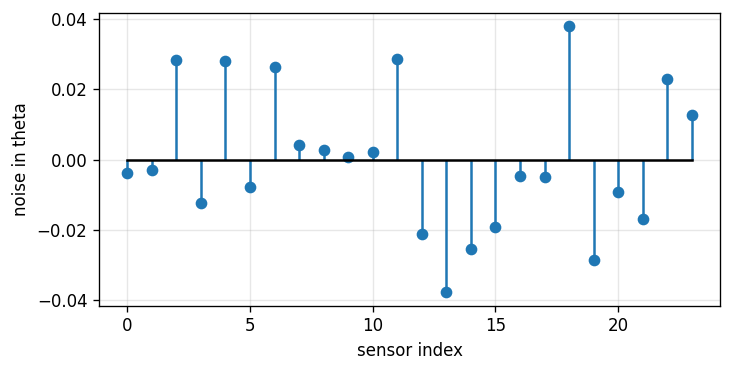

In [6]:
CONFIG = {

    "seed": SEED,

    # Collocation Points
    "sampling": "lhs",       # "lhs" or "sobol"
    "boundary_mode": "uniform",
    "n_domain": 3000,
    "n_boundary": 400,

    # Sensor Placement
    "sensor_x": [0.02, 0.10, 0.18, 0.28, 0.38, 0.44, 0.50, 0.56, 0.62, 0.72, 0.82, 0.90, 0.98],
    "sensor_y": [0.99, 1.00],

    # Sensor Noise
    "use_noisy_sensor": USE_NOISY_SENSOR,
    "noise_level_theta": NOISE_LEVEL_THETA,
    "noise_seed": NOISE_SEED,
}

WEIGHTS = {
    "pde": 1.0,
    "bottom": 10.0,
    "top": 50.0,
    "side": 10.0,
    "data": 100.0,
    "theta_y_data": 10.0,
    "smooth": 0.0,  # auxiliary NN natural spectral bias provides smoothness.
}

sensor_xy = make_sensor_points(CONFIG["sensor_x"], CONFIG["sensor_y"])
theta_sensor = sample_bilinear(xs, ys, theta_ref, sensor_xy)
theta_sensor_clean = theta_sensor.copy()
theta_sensor_noise = gaussian_sensor_noise(
    theta_sensor_clean.shape,
    CONFIG["noise_level_theta"],
    CONFIG["noise_seed"],
)
theta_sensor_train = theta_sensor_clean + theta_sensor_noise if CONFIG["use_noisy_sensor"] else theta_sensor_clean.copy()
theta_y_lower_xy, theta_y_upper_xy, theta_y_pair_xy, theta_y_sensor_ref = build_sensor_theta_y_fd_data(
    sensor_xy,
    theta_sensor_train,
)
x_sensor_t = torch.tensor(sensor_xy, dtype=torch.float64, device=DEVICE)
theta_sensor_t = torch.tensor(theta_sensor_train, dtype=torch.float64, device=DEVICE)
theta_y_lower_t = torch.tensor(theta_y_lower_xy, dtype=torch.float64, device=DEVICE)
theta_y_upper_t = torch.tensor(theta_y_upper_xy, dtype=torch.float64, device=DEVICE)
theta_y_sensor_t = torch.tensor(theta_y_sensor_ref, dtype=torch.float64, device=DEVICE)

xy_f, boundary = make_training_points(
    n_domain=CONFIG["n_domain"],
    n_boundary=CONFIG["n_boundary"],
    sampling=CONFIG["sampling"],
    boundary_mode=CONFIG["boundary_mode"],
    seed=CONFIG["seed"],
)

print("interior collocation:", tuple(xy_f.shape))
for key, value in boundary.items():
    print(f"{key:>6s} boundary:", tuple(value.shape))
print("weights:", WEIGHTS)
print("sensor count:", len(sensor_xy))
print("theta_y FD pair count:", len(theta_y_sensor_ref))
print("sensor x:", CONFIG["sensor_x"])
print("sensor y:", CONFIG["sensor_y"])
print(f"use noisy sensor: {CONFIG['use_noisy_sensor']}")
print(f"sensor noise std theta: {theta_sensor_noise.std():.4e}")
print(f"sensor noise std C    : {(theta_sensor_noise * (T_B - T_INF)).std():.4e}")
print(f"clean/train max diff  : {np.abs(theta_sensor_train - theta_sensor_clean).max():.4e}")
if len(theta_y_sensor_ref):
    print(f"theta_y FD ref range  : {theta_y_sensor_ref.min():.4e} to {theta_y_sensor_ref.max():.4e}")
else:
    print("theta_y FD ref range  : no vertically paired sensor points; theta_y_data loss is zero")

plt.figure(figsize=(6.2, 3.2), dpi=120)
plt.stem(np.arange(len(theta_sensor_noise)), theta_sensor_noise.ravel(), basefmt="k-")
plt.xlabel("sensor index")
plt.ylabel("noise in theta")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:
N_ADAM = 15000
PRINT_EVERY = 500
PINN_LR = 5e-4
BI_LR = 3e-3
ADAM_ETA_MIN = 1e-5
OPTIMIZER_CONFIG = {
    "n_adam": N_ADAM,
    "pinn_lr": PINN_LR,
    "bi_lr": BI_LR,
    "adam_eta_min": ADAM_ETA_MIN,
}

# optimizer: Adam, scheduler: CosineAnnealing
optimizer = torch.optim.Adam(
    [
        {"params": pinn.parameters(), "lr": PINN_LR},
        {"params": bi_top_model.parameters(), "lr": BI_LR},
    ]
)
scheduler = CosineAnnealingLR(optimizer, T_max=N_ADAM, eta_min=ADAM_ETA_MIN)
print("optimizer:", OPTIMIZER_CONFIG)

history = []
t0 = time.perf_counter()

for epoch in range(1, N_ADAM + 1):
    pinn.train()
    bi_top_model.train()
    optimizer.zero_grad(set_to_none=True)
    total_loss, parts = pinn_inverse_loss(pinn, bi_top_model, xy_f, boundary, WEIGHTS)
    total_loss.backward()
    optimizer.step()
    scheduler.step()

    row = {"epoch": epoch, "total": float(total_loss.detach().cpu())}
    row.update({name: float(value.detach().cpu()) for name, value in parts.items()})
    history.append(row)

    if epoch == 1 or epoch % PRINT_EVERY == 0:
        elapsed = time.perf_counter() - t0
        print(
            f"Adam {epoch:6d} | L={row['total']:.3e} "
            f"PDE={row['pde']:.2e} Bot={row['bottom']:.2e} Top={row['top']:.2e} "
            f"Side={row['side']:.2e} Data={row['data']:.2e} dTy={row['theta_y_data']:.2e} "
            f"Smooth={row.get('smooth', 0.0):.2e} | "
            f"{bi_model_status(bi_top_model)} | {elapsed:.1f}s"
        )


optimizer: {'n_adam': 15000, 'pinn_lr': 0.0005, 'bi_lr': 0.003, 'adam_eta_min': 1e-05}
Adam      1 | L=5.958e+01 PDE=6.04e-01 Bot=8.96e-01 Top=3.84e-01 Side=1.30e-02 Data=2.28e-01 dTy=7.87e-01 Smooth=0.00e+00 | Bi[min,max]=(0.492, 0.499) | 0.2s


/home/jinooson/venv/dl_study/lib/python3.12/site-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Adam    500 | L=2.563e-01 PDE=3.62e-02 Bot=6.76e-05 Top=2.81e-05 Side=4.62e-04 Data=3.12e-04 dTy=1.82e-02 Smooth=4.55e-03 | Bi[min,max]=(0.504, 0.518) | 16.8s
Adam   1000 | L=2.378e-01 PDE=2.73e-02 Bot=2.52e-05 Top=2.29e-05 Side=9.47e-04 Data=2.73e-04 dTy=1.72e-02 Smooth=3.18e-02 | Bi[min,max]=(0.484, 0.531) | 33.6s
Adam   1500 | L=2.250e-01 PDE=2.30e-02 Bot=4.55e-05 Top=7.62e-06 Side=1.52e-03 Data=2.35e-04 dTy=1.62e-02 Smooth=1.48e-01 | Bi[min,max]=(0.468, 0.539) | 50.3s
Adam   2000 | L=2.118e-01 PDE=2.22e-02 Bot=1.21e-04 Top=2.94e-06 Side=2.01e-03 Data=1.95e-04 dTy=1.49e-02 Smooth=2.78e-01 | Bi[min,max]=(0.461, 0.55) | 66.9s
Adam   2500 | L=1.885e-01 PDE=2.55e-02 Bot=9.63e-05 Top=3.31e-06 Side=2.22e-03 Data=1.30e-04 dTy=1.27e-02 Smooth=6.29e-01 | Bi[min,max]=(0.438, 0.561) | 83.6s
Adam   3000 | L=1.472e-01 PDE=3.64e-02 Bot=2.58e-05 Top=1.43e-05 Side=1.51e-03 Data=6.55e-05 dTy=8.82e-03 Smooth=2.73e+00 | Bi[min,max]=(0.395, 0.587) | 100.2s
Adam   3500 | L=1.178e-01 PDE=3.21e-02 Bot=1.9

## 6. L-BFGS Fine Tuning

L-BFGS is applied after Adam using the same fixed collocation/boundary points. This usually improves PDE and boundary residual convergence.

In [8]:
RUN_LBFGS = True
LBFGS_STEPS = 1500

if RUN_LBFGS:
    optimizer_lbfgs = torch.optim.LBFGS(
        list(pinn.parameters()) + list(bi_top_model.parameters()),
        lr=0.5,
        max_iter=20,
        history_size=50,
        line_search_fn="strong_wolfe",
    )

    def closure():
        optimizer_lbfgs.zero_grad(set_to_none=True)
        loss, _ = pinn_inverse_loss(pinn, bi_top_model, xy_f, boundary, WEIGHTS)
        loss.backward()
        return loss

    for step in range(1, LBFGS_STEPS + 1):
        loss_value = optimizer_lbfgs.step(closure)
        if step == 1 or step % 50 == 0:
            total_loss, parts = pinn_inverse_loss(pinn, bi_top_model, xy_f, boundary, WEIGHTS)
            row = {"epoch": N_ADAM + step, "total": float(total_loss.detach().cpu())}
            row.update({name: float(value.detach().cpu()) for name, value in parts.items()})
            history.append(row)
            print(
                f"L-BFGS {step:4d} | L={row['total']:.3e} "
                f"PDE={row['pde']:.2e} Top={row['top']:.2e} Data={row['data']:.2e} "
                f"dTy={row['theta_y_data']:.2e} Smooth={row.get('smooth', 0.0):.2e} | "
                f"{bi_model_status(bi_top_model)}"
            )


L-BFGS    1 | L=3.225e-02 PDE=2.18e-03 Top=1.66e-06 Data=5.32e-06 dTy=2.73e-03 Smooth=1.46e+01 | Bi[min,max]=(0.278, 0.689)
L-BFGS   50 | L=2.624e-02 PDE=2.98e-04 Top=7.21e-07 Data=3.75e-06 dTy=2.54e-03 Smooth=1.71e+01 | Bi[min,max]=(0.262, 0.676)
L-BFGS  100 | L=2.571e-02 PDE=1.66e-04 Top=6.12e-07 Data=3.67e-06 dTy=2.51e-03 Smooth=1.79e+01 | Bi[min,max]=(0.259, 0.678)
L-BFGS  150 | L=2.461e-02 PDE=3.93e-04 Top=3.66e-06 Data=3.35e-06 dTy=2.36e-03 Smooth=2.53e+01 | Bi[min,max]=(0.251, 0.684)
L-BFGS  200 | L=1.676e-02 PDE=2.06e-03 Top=1.85e-05 Data=1.48e-06 dTy=1.34e-03 Smooth=1.73e+02 | Bi[min,max]=(0.229, 0.719)
L-BFGS  250 | L=4.032e-03 PDE=1.35e-03 Top=1.59e-05 Data=2.71e-07 dTy=1.70e-04 Smooth=1.00e+03 | Bi[min,max]=(0.268, 0.796)
L-BFGS  300 | L=1.322e-03 PDE=6.80e-04 Top=6.04e-06 Data=8.36e-08 dTy=2.61e-05 Smooth=1.49e+03 | Bi[min,max]=(0.275, 0.813)
L-BFGS  350 | L=8.068e-04 PDE=4.29e-04 Top=2.90e-06 Data=7.51e-08 dTy=1.78e-05 Smooth=1.58e+03 | Bi[min,max]=(0.271, 0.817)
L-BFGS  

## 7. FDM Benchmark and Error Maps

The trained PINN is compared against the FDM reference on the same grid, producing field and error maps.

In [9]:
pinn.eval()
bi_top_model.eval()

xx, yy = np.meshgrid(xs, ys)
xy_eval = np.column_stack([xx.ravel(), yy.ravel()])

with torch.no_grad():
    theta_pred = pinn(torch.tensor(xy_eval, dtype=torch.float64, device=DEVICE)).cpu().numpy().reshape(len(ys), len(xs))
    sensor_pred = pinn(x_sensor_t).cpu().numpy()
    if theta_y_sensor_t.numel():
        theta_y_sensor_pred = (
            (pinn(theta_y_upper_t) - pinn(theta_y_lower_t))
            / (theta_y_upper_t[:, 1:2] - theta_y_lower_t[:, 1:2])
        ).cpu().numpy()
    else:
        theta_y_sensor_pred = np.empty((0, 1), dtype=float)

abs_err = np.abs(theta_pred - theta_ref)
rel_l2 = np.linalg.norm(theta_pred.ravel() - theta_ref.ravel()) / np.linalg.norm(theta_ref.ravel())
max_abs = abs_err.max()
sensor_clean_max_abs = np.max(np.abs(sensor_pred - theta_sensor_clean))
sensor_train_max_abs = np.max(np.abs(sensor_pred - theta_sensor_train))
sensor_theta_y_max_abs = (
    np.max(np.abs(theta_y_sensor_pred - theta_y_sensor_ref))
    if len(theta_y_sensor_ref)
    else float("nan")
)

print(f"field relative L2 error: {rel_l2:.4e}")
print(f"field max abs error    : {max_abs:.4e}")
print(f"sensor clean max abs   : {sensor_clean_max_abs:.4e}")
print(f"sensor train max abs   : {sensor_train_max_abs:.4e}")
print(f"sensor theta_y max abs : {sensor_theta_y_max_abs:.4e}")


field relative L2 error: 2.0311e-04
field max abs error    : 1.3491e-03
sensor clean max abs   : 2.6950e-04
sensor train max abs   : 2.6950e-04
sensor theta_y max abs : 1.1020e-03


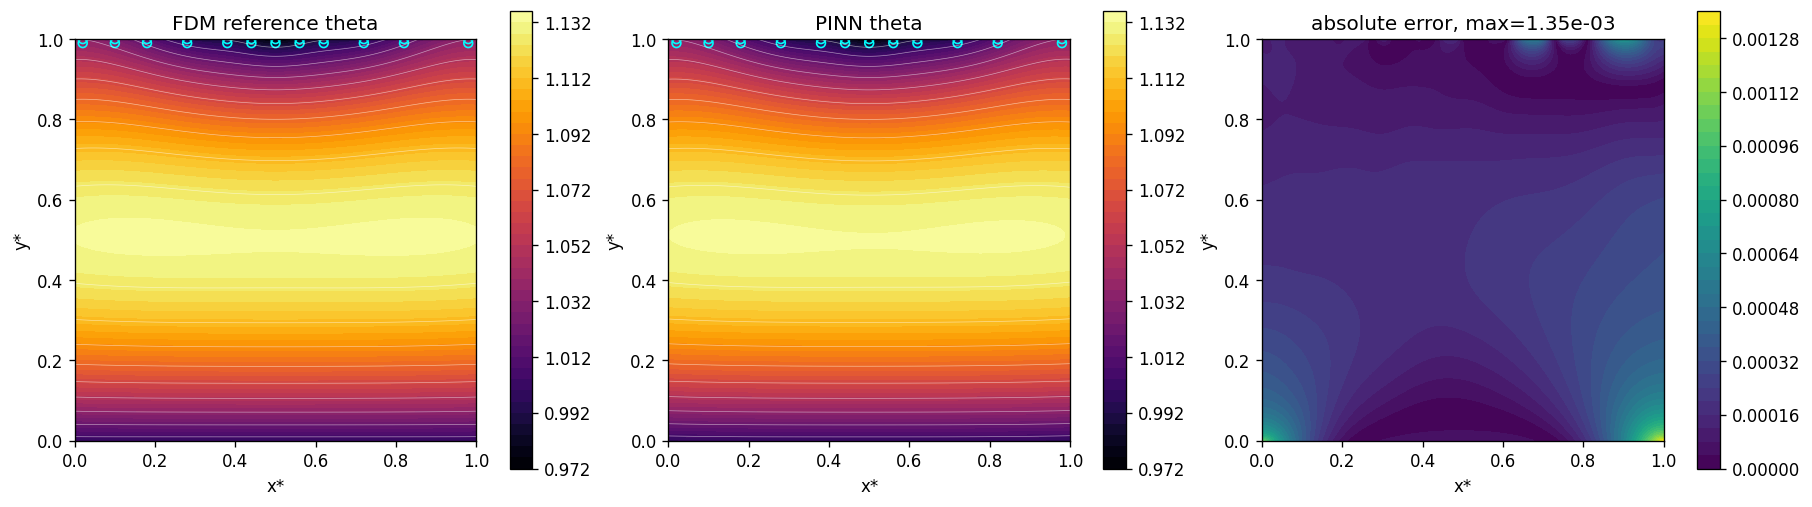

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=120, constrained_layout=True)
levels = 40

im0 = axes[0].contourf(xs, ys, theta_ref, levels=levels, cmap="inferno")
axes[0].contour(xs, ys, theta_ref, levels=10, colors="white", linewidths=0.4, alpha=0.55)
axes[0].scatter(sensor_xy[:, 0], sensor_xy[:, 1], s=28, facecolor="none", edgecolor="cyan", linewidth=1.0)
axes[0].set_title("FDM reference theta")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].contourf(xs, ys, theta_pred, levels=levels, cmap="inferno")
axes[1].contour(xs, ys, theta_pred, levels=10, colors="white", linewidths=0.4, alpha=0.55)
axes[1].scatter(sensor_xy[:, 0], sensor_xy[:, 1], s=28, facecolor="none", edgecolor="cyan", linewidth=1.0)
axes[1].set_title("PINN theta")
fig.colorbar(im1, ax=axes[1])

im2 = axes[2].contourf(xs, ys, abs_err, levels=levels, cmap="viridis")
axes[2].set_title(f"absolute error, max={max_abs:.2e}")
fig.colorbar(im2, ax=axes[2])

for ax in axes:
    ax.set_xlabel("x*")
    ax.set_ylabel("y*")
    ax.set_aspect("equal")

plt.show()


## 8. Recovered `Bi_top` Profile


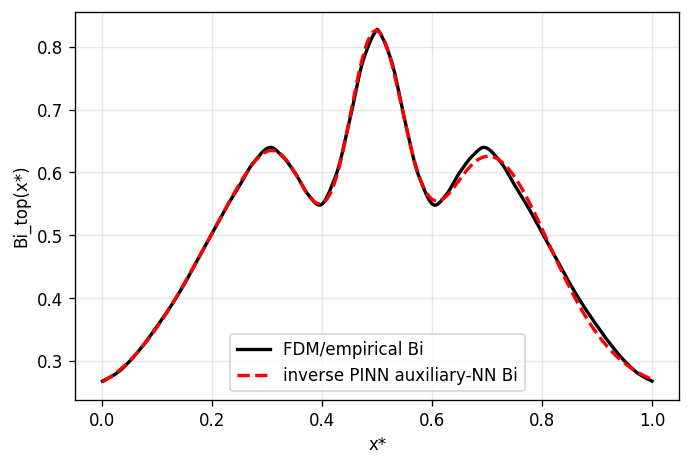

Bi relative L2 error: 1.1218e-02
learned Bi model parameters:
  bi_nn_probe_00 x=0.000: 0.26650261
  bi_nn_probe_01 x=0.050: 0.30078433
  bi_nn_probe_02 x=0.100: 0.35464269
  bi_nn_probe_03 x=0.150: 0.42518083
  bi_nn_probe_04 x=0.200: 0.50402204
  bi_nn_probe_05 x=0.250: 0.58263802
  bi_nn_probe_06 x=0.300: 0.63371301
  bi_nn_probe_07 x=0.350: 0.59985522
  bi_nn_probe_08 x=0.400: 0.55117021
  bi_nn_probe_09 x=0.450: 0.68658212
  bi_nn_probe_10 x=0.500: 0.82549880
  bi_nn_probe_11 x=0.550: 0.68254104
  bi_nn_probe_12 x=0.600: 0.55740502
  bi_nn_probe_13 x=0.650: 0.58855497
  bi_nn_probe_14 x=0.700: 0.62574897
  bi_nn_probe_15 x=0.750: 0.59304287
  bi_nn_probe_16 x=0.800: 0.51011309
  bi_nn_probe_17 x=0.850: 0.41700625
  bi_nn_probe_18 x=0.900: 0.34333031
  bi_nn_probe_19 x=0.950: 0.29651734
  bi_nn_probe_20 x=1.000: 0.27083298


In [11]:
x_plot = np.linspace(0.0, 1.0, 501)[:, None]
with torch.no_grad():
    bi_pred = bi_top_model(torch.tensor(x_plot, dtype=torch.float64, device=DEVICE)).cpu().numpy().ravel()

bi_true = true_bi_numpy(x_plot.ravel())
bi_rel_l2 = np.linalg.norm(bi_pred - bi_true) / np.linalg.norm(bi_true)

plt.figure(figsize=(6.5, 4.2), dpi=120)
plt.plot(x_plot.ravel(), bi_true, "k-", lw=2, label="FDM/empirical Bi")
plt.plot(x_plot.ravel(), bi_pred, "r--", lw=2, label=bi_model_label(BI_MODEL_CONFIG))
if hasattr(bi_top_model, "x_nodes"):
    plt.plot(
        bi_top_model.x_nodes.detach().cpu().numpy(),
        bi_top_model.physical_params().detach().cpu().numpy(),
        "ro",
        ms=3.5,
        label="trainable nodes",
    )
plt.xlabel("x*")
plt.ylabel("Bi_top(x*)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f"Bi relative L2 error: {bi_rel_l2:.4e}")
print("learned Bi model parameters:")
print_bi_model_parameters(bi_top_model, BI_PARAM_NAMES)


## 9. Loss History

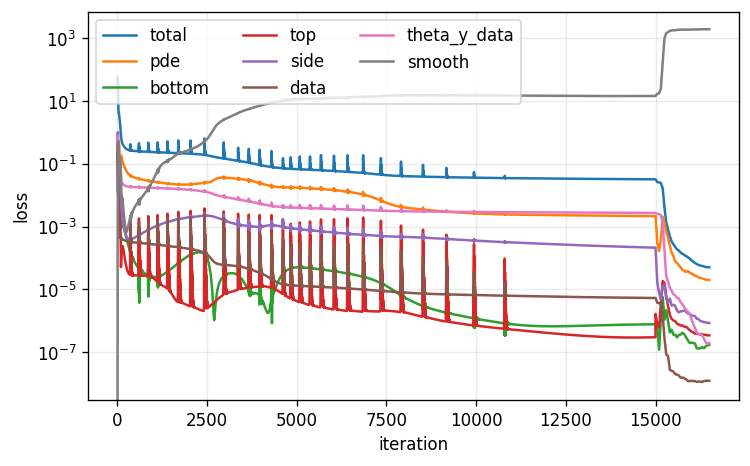

In [12]:
if history:
    epochs = np.array([row["epoch"] for row in history])
    plt.figure(figsize=(7.0, 4.2), dpi=120)
    for key in ["total", "pde", "bottom", "top", "side", "data", "theta_y_data", "smooth"]:
        vals = np.array([row[key] for row in history if key in row])
        plt.semilogy(epochs[:len(vals)], vals, label=key)
    plt.xlabel("iteration")
    plt.ylabel("loss")
    plt.grid(True, which="both", alpha=0.25)
    plt.legend(ncol=3)
    plt.show()


## 10. Save Results

In [13]:
OUTDIR = REF_PATH.parent.parent / "pinn_inverse_output"
OUTDIR.mkdir(parents=True, exist_ok=True)
BI_MODEL_SLUG = bi_model_slug(BI_MODEL_CONFIG)
RUN_ID = time.strftime(
    f"run_%Y%m%d_%H%M%S_{BI_MODEL_SLUG}_"
    + f"{CONFIG['sampling']}_Nf{CONFIG['n_domain']}_Nb{CONFIG['n_boundary']}_seed{CONFIG['seed']}"
)
RUN_DIR = OUTDIR / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

bi_param_values = bi_model_values(bi_top_model)
bi_node_x = None
bi_node_values = None
h_node_values = None
bi_probe_x = None
bi_probe_values = None
h_probe_values = None
if hasattr(bi_top_model, "x_nodes"):
    bi_node_x = bi_top_model.x_nodes.detach().cpu().numpy()
    bi_node_values = np.asarray(bi_param_values, dtype=float)
    h_node_values = bi_node_values * K_S / L
elif hasattr(bi_top_model, "x_probe"):
    bi_probe_x = bi_top_model.x_probe.detach().cpu().numpy()
    bi_probe_values = np.asarray(bi_param_values, dtype=float)
    h_probe_values = bi_probe_values * K_S / L
checkpoint = {
    "pinn_state_dict": pinn.state_dict(),
    "bi_top_state_dict": bi_top_model.state_dict(),
    "bi_model_config": BI_MODEL_CONFIG,
    "bi_param_names": BI_PARAM_NAMES,
    "bi_param_values": bi_param_values,
    "config": CONFIG,
    "weights": WEIGHTS,
    "optimizer_config": OPTIMIZER_CONFIG,
    "run_id": RUN_ID,
    "sensor_count": int(len(sensor_xy)),
    "sensor_xy": sensor_xy.tolist(),
    "theta_y_fd_pair_count": int(len(theta_y_sensor_ref)),
    "theta_y_pair_xy": theta_y_pair_xy.tolist(),
    "history": history,
    "rel_l2": float(rel_l2),
    "max_abs": float(max_abs),
    "sensor_clean_max_abs": float(sensor_clean_max_abs),
    "sensor_train_max_abs": float(sensor_train_max_abs),
    "sensor_theta_y_max_abs": float(sensor_theta_y_max_abs),
    "bi_rel_l2": float(bi_rel_l2),
    "use_noisy_sensor": bool(CONFIG["use_noisy_sensor"]),
    "noise_level_theta": float(CONFIG["noise_level_theta"]),
    "noise_seed": int(CONFIG["noise_seed"]),
    "h_min_guess": float(H_MIN_GUESS),
    "h_max_guess": float(H_MAX_GUESS),
    "init_bi_min": float(INIT_BI_MIN),
    "init_bi_max": float(INIT_BI_MAX),
}
if bi_node_x is not None:
    checkpoint.update(
        {
            "bi_node_x": bi_node_x.tolist(),
            "bi_node_values": bi_node_values.tolist(),
            "h_node_values": h_node_values.tolist(),
        }
    )
if bi_probe_x is not None:
    checkpoint.update(
        {
            "bi_probe_x": bi_probe_x.tolist(),
            "bi_probe_values": bi_probe_values.tolist(),
            "h_probe_values": h_probe_values.tolist(),
        }
    )
torch.save(checkpoint, RUN_DIR / f"pinn_inverse_{BI_MODEL_SLUG}.pt")

with open(RUN_DIR / "run_summary.json", "w") as f:
    run_summary = {
        "run_id": RUN_ID,
        "bi_model_config": BI_MODEL_CONFIG,
        "config": CONFIG,
        "weights": WEIGHTS,
        "optimizer_config": OPTIMIZER_CONFIG,
        "sensor_count": int(len(sensor_xy)),
        "sensor_xy": sensor_xy.tolist(),
        "theta_y_fd_pair_count": int(len(theta_y_sensor_ref)),
        "theta_y_pair_xy": theta_y_pair_xy.tolist(),
        "bi_param_names": BI_PARAM_NAMES,
        "bi_param_values": bi_param_values,
        "rel_l2": float(rel_l2),
        "max_abs": float(max_abs),
        "sensor_clean_max_abs": float(sensor_clean_max_abs),
        "sensor_train_max_abs": float(sensor_train_max_abs),
        "sensor_theta_y_max_abs": float(sensor_theta_y_max_abs),
        "bi_rel_l2": float(bi_rel_l2),
        "h_min_guess": float(H_MIN_GUESS),
        "h_max_guess": float(H_MAX_GUESS),
        "init_bi_min": float(INIT_BI_MIN),
        "init_bi_max": float(INIT_BI_MAX),
    }
    if bi_node_x is not None:
        run_summary.update(
            {
                "bi_node_x": checkpoint["bi_node_x"],
                "bi_node_values": checkpoint["bi_node_values"],
                "h_node_values": checkpoint["h_node_values"],
            }
        )
    if bi_probe_x is not None:
        run_summary.update(
            {
                "bi_probe_x": checkpoint["bi_probe_x"],
                "bi_probe_values": checkpoint["bi_probe_values"],
                "h_probe_values": checkpoint["h_probe_values"],
            }
        )
    json.dump(run_summary, f, indent=2)

if history:
    with open(RUN_DIR / "loss_history.csv", "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)

with open(RUN_DIR / "sensor_data.csv", "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["sensor_id", "x_star", "y_star", "theta_clean", "theta_train", "theta_noise", "theta_pred"],
    )
    writer.writeheader()
    for sensor_id, ((x, y), clean, train, noise, pred) in enumerate(
        zip(
            sensor_xy,
            theta_sensor_clean.ravel(),
            theta_sensor_train.ravel(),
            theta_sensor_noise.ravel(),
            sensor_pred.ravel(),
        )
    ):
        writer.writerow(
            {
                "sensor_id": sensor_id,
                "x_star": float(x),
                "y_star": float(y),
                "theta_clean": float(clean),
                "theta_train": float(train),
                "theta_noise": float(noise),
                "theta_pred": float(pred),
            }
        )

with open(RUN_DIR / "theta_y_fd_pairs.csv", "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "pair_id",
            "x_star",
            "y_lower",
            "y_upper",
            "theta_y_fd_ref",
            "theta_y_fd_pred",
        ],
    )
    writer.writeheader()
    for pair_id, (lower_xy, upper_xy, theta_y_ref_i, theta_y_pred_i) in enumerate(
        zip(theta_y_lower_xy, theta_y_upper_xy, theta_y_sensor_ref.ravel(), theta_y_sensor_pred.ravel())
    ):
        writer.writerow(
            {
                "pair_id": pair_id,
                "x_star": float(theta_y_pair_xy[pair_id, 0]),
                "y_lower": float(lower_xy[1]),
                "y_upper": float(upper_xy[1]),
                "theta_y_fd_ref": float(theta_y_ref_i),
                "theta_y_fd_pred": float(theta_y_pred_i),
            }
        )

np.savez_compressed(
    RUN_DIR / f"pinn_inverse_{BI_MODEL_SLUG}_fields.npz",
    xs=xs,
    ys=ys,
    theta_ref=theta_ref,
    theta_pred=theta_pred,
    abs_err=abs_err,
    sensor_xy=sensor_xy,
    theta_sensor=theta_sensor,
    theta_sensor_clean=theta_sensor_clean,
    theta_sensor_train=theta_sensor_train,
    theta_sensor_noise=theta_sensor_noise,
    theta_sensor_pred=sensor_pred,
    theta_y_lower_xy=theta_y_lower_xy,
    theta_y_upper_xy=theta_y_upper_xy,
    theta_y_pair_xy=theta_y_pair_xy,
    theta_y_sensor_ref=theta_y_sensor_ref,
    theta_y_sensor_pred=theta_y_sensor_pred,
    use_noisy_sensor=CONFIG["use_noisy_sensor"],
    noise_level_theta=CONFIG["noise_level_theta"],
    noise_seed=CONFIG["noise_seed"],
    h_min_guess=H_MIN_GUESS,
    h_max_guess=H_MAX_GUESS,
    init_bi_min=INIT_BI_MIN,
    init_bi_max=INIT_BI_MAX,
    bi_model_type=BI_MODEL_CONFIG["type"],
    bi_param_names=np.asarray(BI_PARAM_NAMES),
    bi_param_values=np.asarray(bi_param_values, dtype=float),
    bi_node_x=np.asarray([] if bi_node_x is None else bi_node_x),
    bi_node_values=np.asarray([] if bi_node_values is None else bi_node_values),
    h_node_values=np.asarray([] if h_node_values is None else h_node_values),
    bi_probe_x=np.asarray([] if bi_probe_x is None else bi_probe_x),
    bi_probe_values=np.asarray([] if bi_probe_values is None else bi_probe_values),
    h_probe_values=np.asarray([] if h_probe_values is None else h_probe_values),
    x_plot=x_plot.ravel(),
    bi_true=bi_true,
    bi_pred=bi_pred,
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=160, constrained_layout=True)
im0 = axes[0].contourf(xs, ys, theta_ref, levels=40, cmap="inferno")
axes[0].contour(xs, ys, theta_ref, levels=10, colors="white", linewidths=0.4, alpha=0.55)
axes[0].scatter(sensor_xy[:, 0], sensor_xy[:, 1], s=28, facecolor="none", edgecolor="cyan", linewidth=1.0)
axes[0].set_title("FDM reference theta")
fig.colorbar(im0, ax=axes[0])
im1 = axes[1].contourf(xs, ys, theta_pred, levels=40, cmap="inferno")
axes[1].contour(xs, ys, theta_pred, levels=10, colors="white", linewidths=0.4, alpha=0.55)
axes[1].scatter(sensor_xy[:, 0], sensor_xy[:, 1], s=28, facecolor="none", edgecolor="cyan", linewidth=1.0)
axes[1].set_title("PINN theta")
fig.colorbar(im1, ax=axes[1])
im2 = axes[2].contourf(xs, ys, abs_err, levels=40, cmap="viridis")
axes[2].set_title(f"absolute error, max={max_abs:.2e}")
fig.colorbar(im2, ax=axes[2])
for ax in axes:
    ax.set_xlabel("x*")
    ax.set_ylabel("y*")
    ax.set_aspect("equal")
fig.savefig(RUN_DIR / "field_comparison.png", bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.5, 4.2), dpi=160)
ax.plot(x_plot.ravel(), bi_true, "k-", lw=2, label="FDM/empirical Bi")
ax.plot(x_plot.ravel(), bi_pred, "r--", lw=2, label=bi_model_label(BI_MODEL_CONFIG))
if bi_node_x is not None:
    ax.plot(bi_node_x, bi_node_values, "ro", ms=3.5, label="trainable nodes")
ax.set_xlabel("x*")
ax.set_ylabel("Bi_top(x*)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.savefig(RUN_DIR / "bi_profile.png", bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.2, 3.2), dpi=160)
ax.stem(np.arange(len(theta_sensor_noise)), theta_sensor_noise.ravel(), basefmt="k-")
ax.set_xlabel("sensor index")
ax.set_ylabel("noise in theta")
ax.grid(True, alpha=0.3)
fig.savefig(RUN_DIR / "sensor_noise.png", bbox_inches="tight")
plt.close(fig)

if history:
    epochs = np.array([row["epoch"] for row in history])
    fig, ax = plt.subplots(figsize=(7.0, 4.2), dpi=160)
    for key in ["total", "pde", "bottom", "top", "side", "data", "theta_y_data", "smooth"]:
        vals = np.array([row[key] for row in history if key in row])
        ax.semilogy(epochs[:len(vals)], vals, label=key)
    ax.set_xlabel("iteration")
    ax.set_ylabel("loss")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(ncol=3)
    fig.savefig(RUN_DIR / "loss_history.png", bbox_inches="tight")
    plt.close(fig)

print("saved run to:", RUN_DIR)


saved run to: /home/jinooson/DL_study/Heat_Transfer_PINN/Final_Project/pinn_inverse_output/run_20260606_131849_auxiliary_nn_lhs_Nf3000_Nb400_seed2026
